# Diabetes Prediction from Health Indicators

Can survey answers about health, lifestyle and income flag people with **diabetes or prediabetes**? As a screening tool, the model focuses on **recall**: missing a person with diabetes costs more than a false alarm.

**Data:** CDC BRFSS 2015 health survey, balanced version (`diabetes_binary_5050split_health_indicators_BRFSS2015.csv`): **70,692 answers, 21 features**, half of them with diabetes or prediabetes. The full survey has 253,680 answers (~14% with diabetes); the balanced file keeps all 35,346 people with diabetes and the same number of people without it.

**Result:** Gradient Boosting on the test set: **recall 0.80**, precision 0.73, ROC-AUC 0.83.

| Section | Content |
|---|---|
| 1. Data | Load the data, check types, missing values and the target balance |
| 2. Exploratory analysis | How each feature differs between people with and without diabetes |
| 3. Feature engineering | New features based on clinical reasoning |
| 4. Feature selection | Drop weak and redundant features (correlation and VIF) |
| 5. Model comparison | 6 models, 5-fold cross-validation |
| 6. Hyperparameter tuning | Logistic Regression and Gradient Boosting |
| 7. Final evaluation | Train vs test, confusion matrices, ROC curve |
| 8. Feature importance | Which features drive the final model |
| 9. Conclusions | Main results and limitations |

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC  
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler, RobustScaler
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay


## 1. Data

In [76]:
df= pd.read_csv("diabetes_binary_5050split_health_indicators_BRFSS2015.csv")
df

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70687,1.0,0.0,1.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,0.0,0.0,6.0,4.0,1.0
70688,1.0,0.0,1.0,1.0,29.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,2.0,0.0,0.0,1.0,1.0,10.0,3.0,6.0
70689,1.0,1.0,1.0,1.0,25.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,15.0,0.0,1.0,0.0,13.0,6.0,4.0
70690,1.0,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0


In [77]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  MentHlth              70692 no

In [78]:
df["Diabetes_binary"].value_counts().sort_index()


Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64

In [79]:
df.select_dtypes("number").nunique()

Diabetes_binary          2
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     80
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
AnyHealthcare            2
NoDocbcCost              2
GenHlth                  5
MentHlth                31
PhysHlth                31
DiffWalk                 2
Sex                      2
Age                     13
Education                6
Income                   8
dtype: int64

- **70,692 rows and 21 features**, all numeric, **no missing values**
- The target is balanced: **35,346** with and **35,346** without diabetes
- 14 features are yes/no (0/1). The others have more values: BMI, GenHlth (1–5), MentHlth and PhysHlth (0–30 days), Age (13 groups), Education (1–6) and Income (1–8)

## 2. Exploratory analysis

Share of people at each value of the non-binary features, for people without (0, blue) and with (1, orange) diabetes.

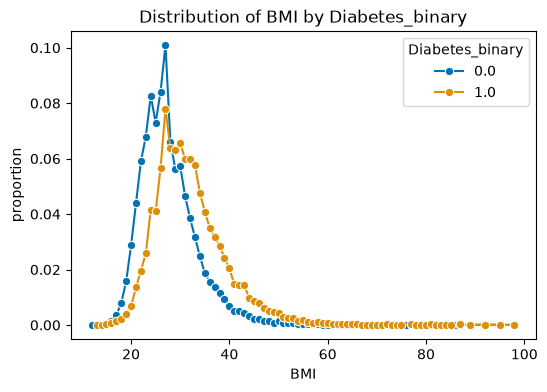

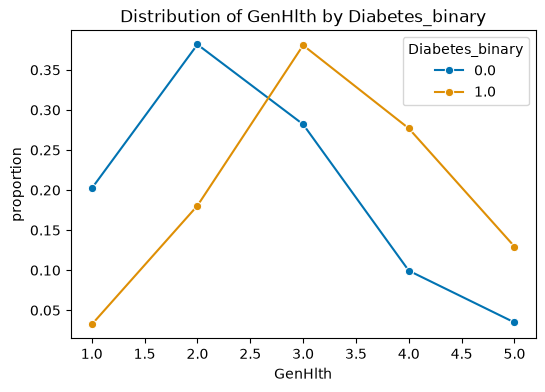

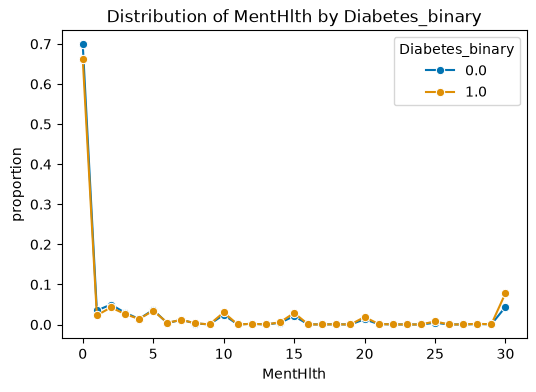

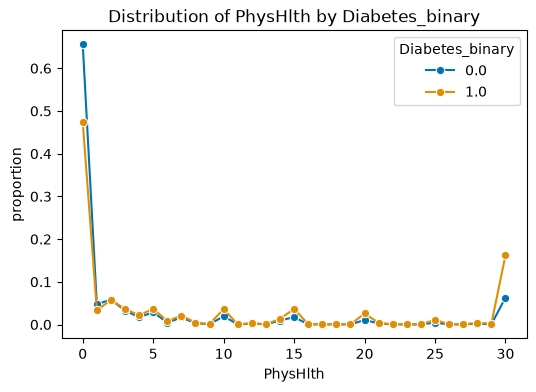

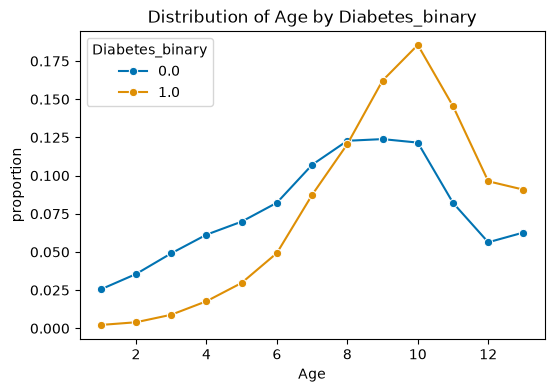

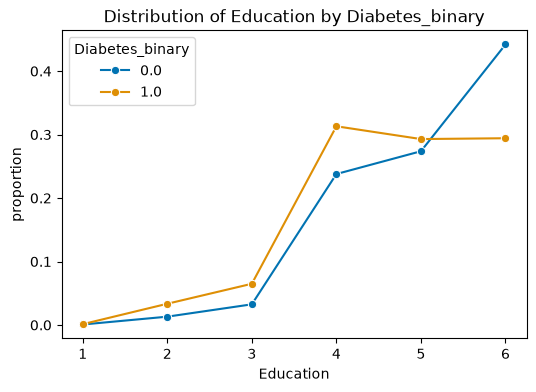

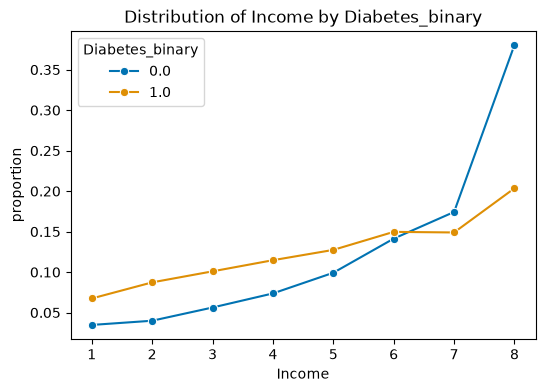

In [80]:
# Distribution of each non-binary feature, by diabetes status
cols_multi = df.columns[(df.nunique() > 2) & (df.columns != "Diabetes_binary")]

palette = {0: "#0173B2", 1: "#DE8F05"}  # blue/orange, colorblind-safe

for col in cols_multi:
    dist = (
        df.groupby("Diabetes_binary")[col]
        .value_counts(normalize=True)
        .rename("proportion")
        .reset_index()
        .sort_values(col)
    )

    plt.figure(figsize=(6, 4))
    sns.lineplot(
        data=dist, x=col, y="proportion", hue="Diabetes_binary",
        palette=palette, marker="o"
    )
    plt.title(f"Distribution of {col} by Diabetes_binary")
    plt.show()


- **BMI:** the curve for people with diabetes is shifted to the right: higher BMI values are much more common
- **General health (GenHlth):** people with diabetes rate their health worse (most common answer 3 "good" vs 2 "very good")
- **Physical health (PhysHlth):** people with diabetes more often report 30 bad days out of 30
- **Age:** diabetes is rare below group 6 (45–49) and most common in groups 9–10 (60–69)
- **Income and education:** lower groups have relatively more people with diabetes; the top groups are mostly people without it
- **Mental health (MentHlth):** almost no difference → a weak feature

## 3. Feature engineering

New features built on clinical reasoning (interactions, scores and clinical cut-offs). Each one is checked against the target with a correlation matrix.

In [81]:
# 1. Interactions
# Clinically meaningful interactions: 
# - BMI * HighBP (combined effect of obesity + hypertension)
# - BMI * HighChol (combined effect of obesity + cholesterol), 
# especially useful if you later use a linear model such as logistic regression.


df["BMI_HighBP"] = df["BMI"] * df["HighBP"]
df["BMI_HighChol"] = df["BMI"] * df["HighChol"]






In [82]:
# 2. Comorbidity score
# add up the binary risk factors 
# (HighBP + HighChol + Stroke + HeartDiseaseorAttack + DiffWalk) 
# into a single risk_score variable — captures the accumulation of conditions, 
# which is usually more predictive than each one on its own.

risk_cols = ["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]

df["risk_score"] = df[risk_cols].sum(axis=1)





In [83]:
# 3. Unhealthy days: MentHlth + PhysHlth (last 30 days)
# Combine MentHlth + PhysHlth into a total of "unhealthy days per month" 
# (UnhealthyDays), since both measure the same thing (days in the last 30) 
# from different angles.

df["UnhealthyDays"] = (df["MentHlth"] + df["PhysHlth"]).clip(upper=30)



In [84]:
# 4. Group BMI into clinical ranges
# (underweight/normal/overweight/obese) instead of keeping it continuous — 
# more interpretable, and it can help linear models capture non-linearities.

df.BMI.unique()

array([26., 28., 29., 18., 31., 32., 27., 24., 21., 58., 30., 20., 22.,
       38., 40., 25., 36., 47., 19., 37., 41., 23., 34., 35., 42., 17.,
       33., 44., 15., 52., 69., 56., 45., 39., 92., 53., 98., 50., 46.,
       79., 48., 16., 63., 72., 54., 49., 68., 43., 84., 73., 76., 55.,
       51., 75., 57., 60., 12., 77., 82., 67., 71., 61., 14., 81., 59.,
       86., 13., 87., 65., 95., 89., 62., 64., 66., 85., 70., 83., 80.,
       78., 74.])

In [85]:
bmi_bins = [0, 18.5, 25, 30, float("inf")]
bmi_labels = ["Underweight", "Normal", "Overweight", "Obese"]

df["BMI_category"] = pd.cut(df["BMI"], bins=bmi_bins, labels=bmi_labels, right=False)

# Drop the first category (Underweight) to avoid collinearity:
# it can be deduced from the other three

df = pd.get_dummies(df, columns=["BMI_category"], drop_first=True)



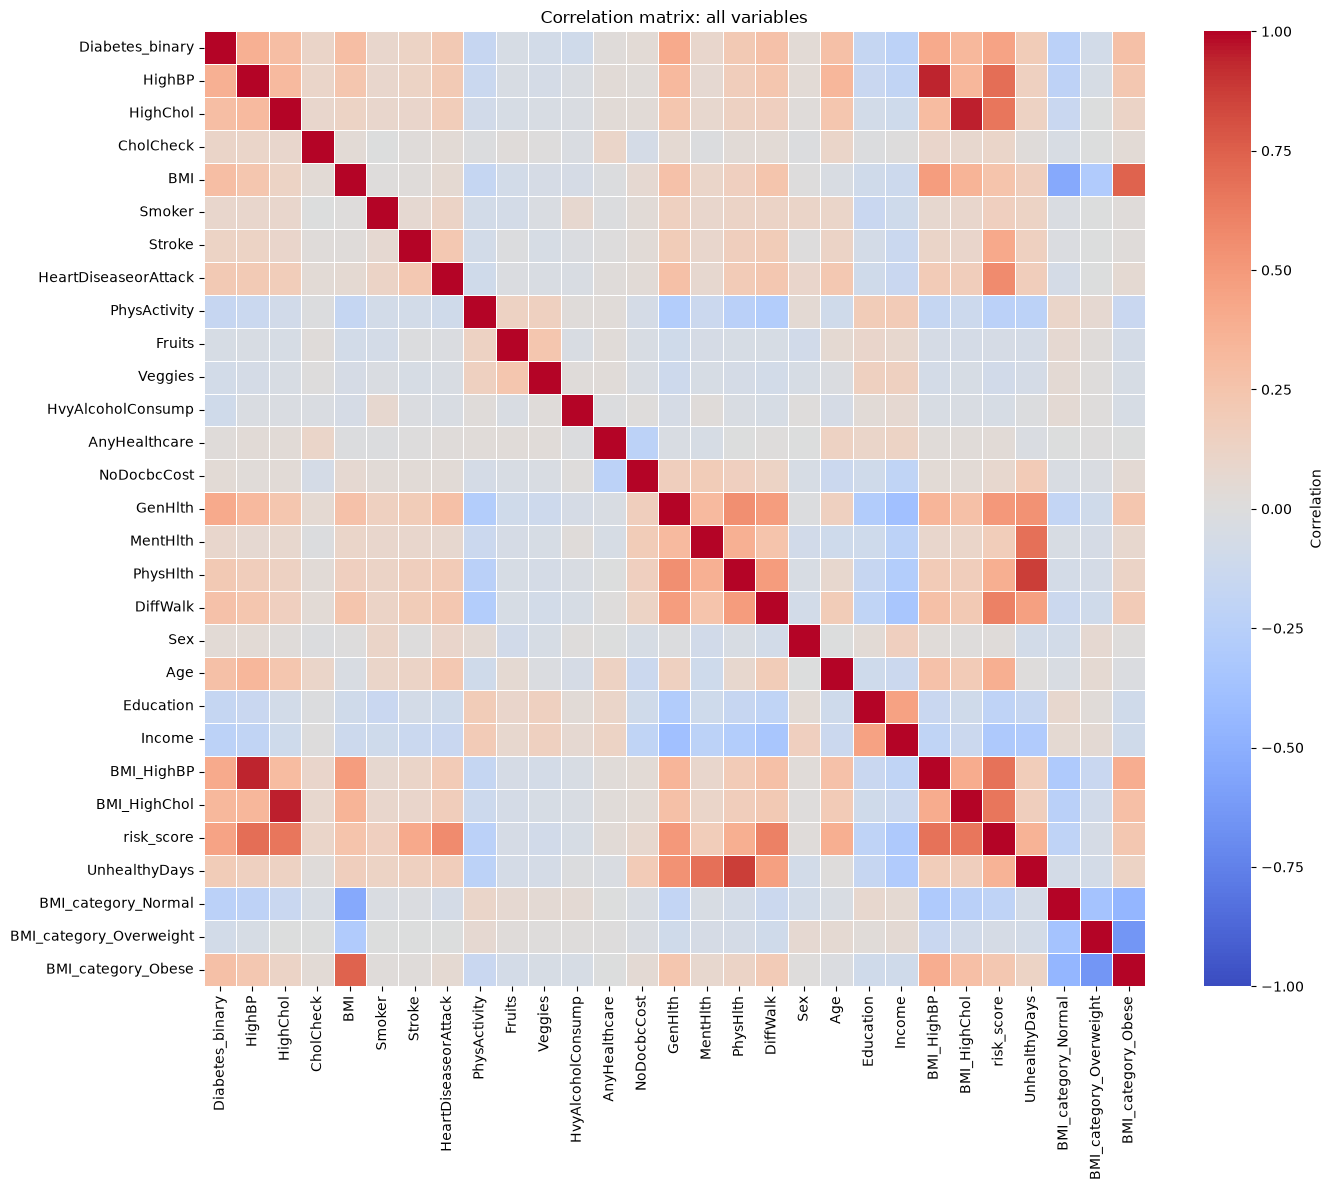

In [86]:
# Correlation matrix: original + new features

numeric_df = df.select_dtypes(include=["number", "bool"])
corr = numeric_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    linewidths=0.5, cbar_kws={"label": "Correlation"}
)
plt.title("Correlation matrix: all variables")
plt.tight_layout()
plt.show()


**How to read the correlation matrix**
- **Target row (`Diabetes_binary`):** which features have the strongest link with diabetes
- **New features vs their parts:** a new feature is only worth keeping if it correlates more with the target than its parts
- **Redundant pairs** (e.g. BMI categories vs BMI): keep one, not both
- **Near-zero correlation with the target:** candidates to drop

In [88]:
corr["Diabetes_binary"].sort_values(ascending=False)

Diabetes_binary            1.000000
risk_score                 0.449149
BMI_HighBP                 0.409085
GenHlth                    0.407612
HighBP                     0.381516
BMI_HighChol               0.328722
BMI                        0.293373
HighChol                   0.289213
Age                        0.278738
BMI_category_Obese         0.275264
DiffWalk                   0.272646
PhysHlth                   0.213081
HeartDiseaseorAttack       0.211523
UnhealthyDays              0.192565
Stroke                     0.125427
CholCheck                  0.115382
MentHlth                   0.087029
Smoker                     0.085999
Sex                        0.044413
NoDocbcCost                0.040977
AnyHealthcare              0.023191
Fruits                    -0.054077
Veggies                   -0.079293
BMI_category_Overweight   -0.082068
HvyAlcoholConsump         -0.094853
PhysActivity              -0.158666
Education                 -0.170481
Income                    -0

- Strongest links: `risk_score` (0.45), `BMI_HighBP` (0.41), `GenHlth` (0.41), `HighBP` (0.38)
- Protective (negative): `Income` (−0.22), `Education` (−0.17), `PhysActivity` (−0.16)

In [90]:
# Smoking interactions

df["Smoker_HeartDisease"] = df["Smoker"] * df["HeartDiseaseorAttack"]
df["Smoker_Age"] = df["Smoker"] * df["Age"]

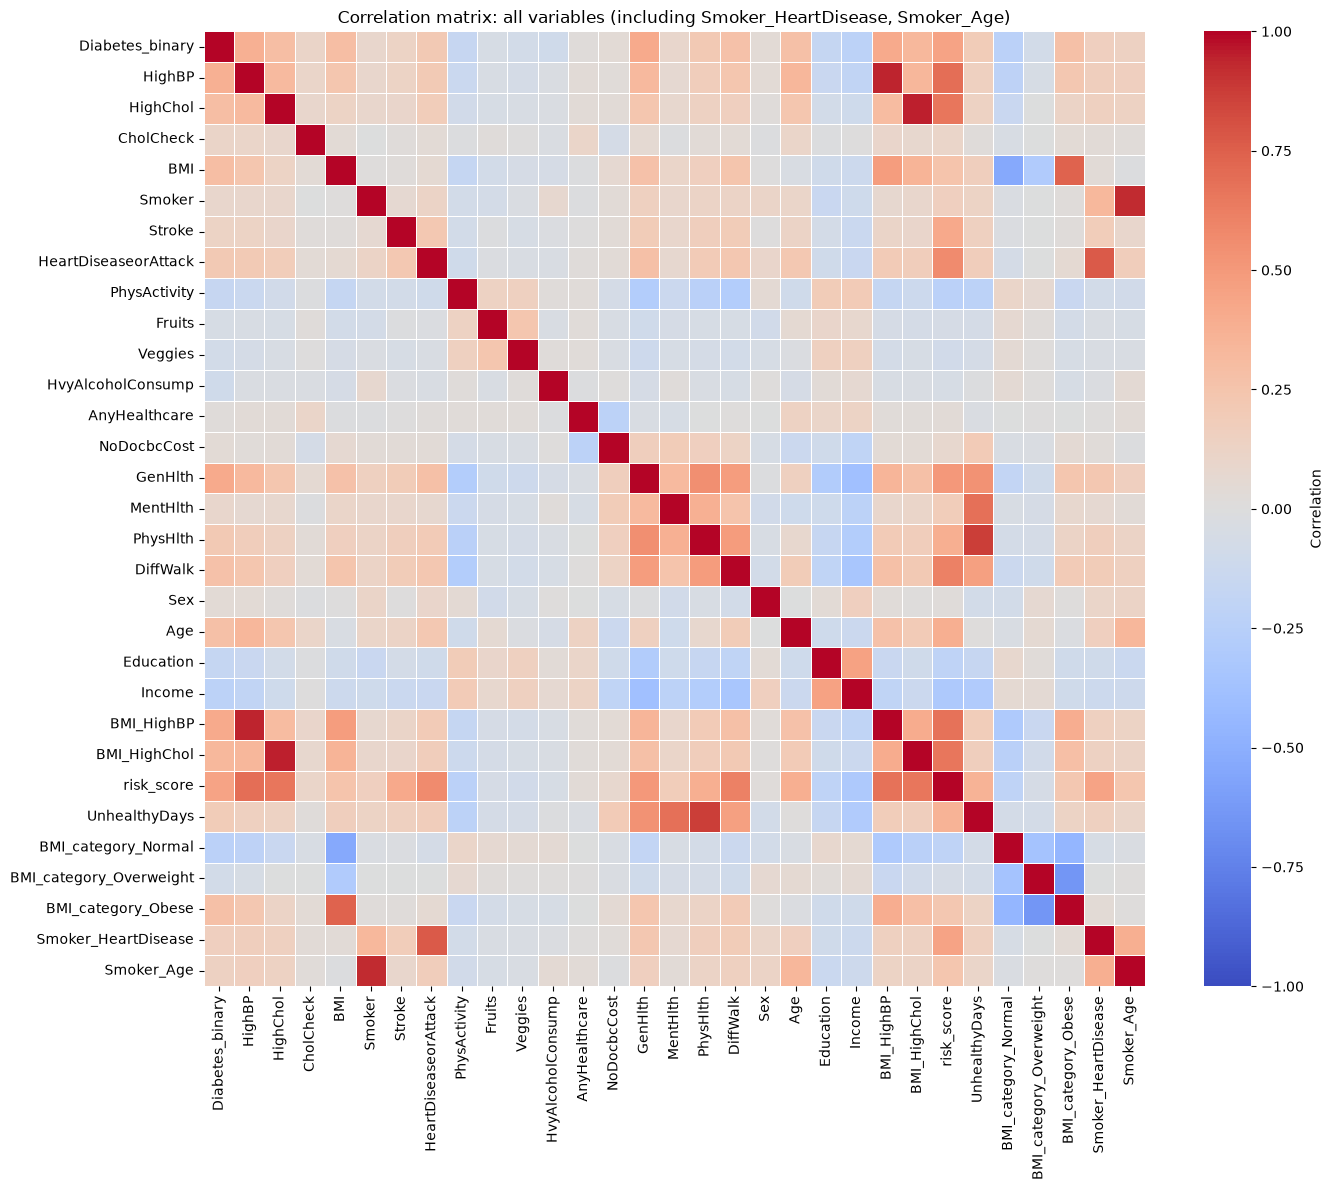

In [91]:
numeric_df = df.select_dtypes(include=["number", "bool"])
corr = numeric_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    linewidths=0.5, cbar_kws={"label": "Correlation"}
)
plt.title("Correlation matrix: all variables (including Smoker_HeartDisease, Smoker_Age)")
plt.tight_layout()
plt.show()

In [92]:
corr["Diabetes_binary"].reindex(corr["Diabetes_binary"].abs().sort_values(ascending=False).index)

Diabetes_binary            1.000000
risk_score                 0.449149
BMI_HighBP                 0.409085
GenHlth                    0.407612
HighBP                     0.381516
BMI_HighChol               0.328722
BMI                        0.293373
HighChol                   0.289213
Age                        0.278738
BMI_category_Obese         0.275264
DiffWalk                   0.272646
BMI_category_Normal       -0.231596
Income                    -0.224449
PhysHlth                   0.213081
HeartDiseaseorAttack       0.211523
UnhealthyDays              0.192565
Education                 -0.170481
Smoker_HeartDisease        0.162790
PhysActivity              -0.158666
Smoker_Age                 0.140787
Stroke                     0.125427
CholCheck                  0.115382
HvyAlcoholConsump         -0.094853
MentHlth                   0.087029
Smoker                     0.085999
BMI_category_Overweight   -0.082068
Veggies                   -0.079293
Fruits                    -0

**Smoking interactions are not used:** `Smoker_Age` (0.14) is weaker than `Age` alone and `Smoker_HeartDisease` (0.16) is weaker than `HeartDiseaseorAttack` alone.

**More clinical features:**

In [94]:
# Age × BMI
df["Age_BMI"] = df["Age"] * df["BMI"]

In [96]:
# Metabolic syndrome proxy: high blood pressure + high cholesterol + BMI ≥ 30
df["MetSyn_count"] = df["HighBP"] + df["HighChol"] + (df["BMI"] >= 30).astype(int)
df["MetSyn_full"]  = (df["MetSyn_count"] == 3).astype(int)

In [97]:
# Age screening cut-offs. The ADA recommends screening everyone from age 35. Age code 4 = 35–39 and code 6 = 45–49.
df["Age_45plus"] = (df["Age"] >= 6).astype(int)

In [98]:
# Frequent distress. The CDC defines "frequent distress" as 14 or more bad days in the last 30. This may work better than the raw day counts.
df["FreqPhysDistress"] = (df["PhysHlth"] >= 14).astype(int)
df["FreqMentDistress"] = (df["MentHlth"] >= 14).astype(int)

In [99]:
# Poor self-rated health. GenHlth 4–5 means "fair" or "poor".
df["PoorHealth"] = (df["GenHlth"] >= 4).astype(int)

In [100]:
# Cardiovascular disease flag. Stroke and heart disease are both rare, so merging them gives a stronger signal.
df["CVD"] = ((df["Stroke"] == 1) | (df["HeartDiseaseorAttack"] == 1)).astype(int)

In [101]:
# Severe obesity and BMI outliers. Risk rises sharply at BMI 40 and above. Values like 92 or 98 are probably errors, so cap them.
df["BMI"] = df["BMI"].clip(upper=60)
df["SevereObese"] = (df["BMI"] >= 40).astype(int)

**Lifestyle and socioeconomic features:**

In [103]:
# Sedentary and obese together. Diabetes prevention programs target exactly this combination.
df["Sedentary_Obese"] = ((df["PhysActivity"] == 0) & (df["BMI"] >= 30)).astype(int)

In [104]:
# Healthy lifestyle score. Fruits, Veggies and HvyAlcoholConsump were each weak on their own, but together they may carry signal.
df["Lifestyle_score"] = df["PhysActivity"] + df["Fruits"] + df["Veggies"] + (1 - df["Smoker"]) + (1 - df["HvyAlcoholConsump"])

In [105]:
# Socioeconomic index. Income and Education are both protective, so combine them.
df["SES"] = df["Income"] / 8 + df["Education"] / 6   # normalised to 0-2

In [106]:
# Age × HighBP. High blood pressure in an older person is a different risk than in a young one.
df["Age_HighBP"] = df["Age"] * df["HighBP"]

In [107]:
numeric_df = df.select_dtypes(include=["number", "bool"])
corr = numeric_df.corr()

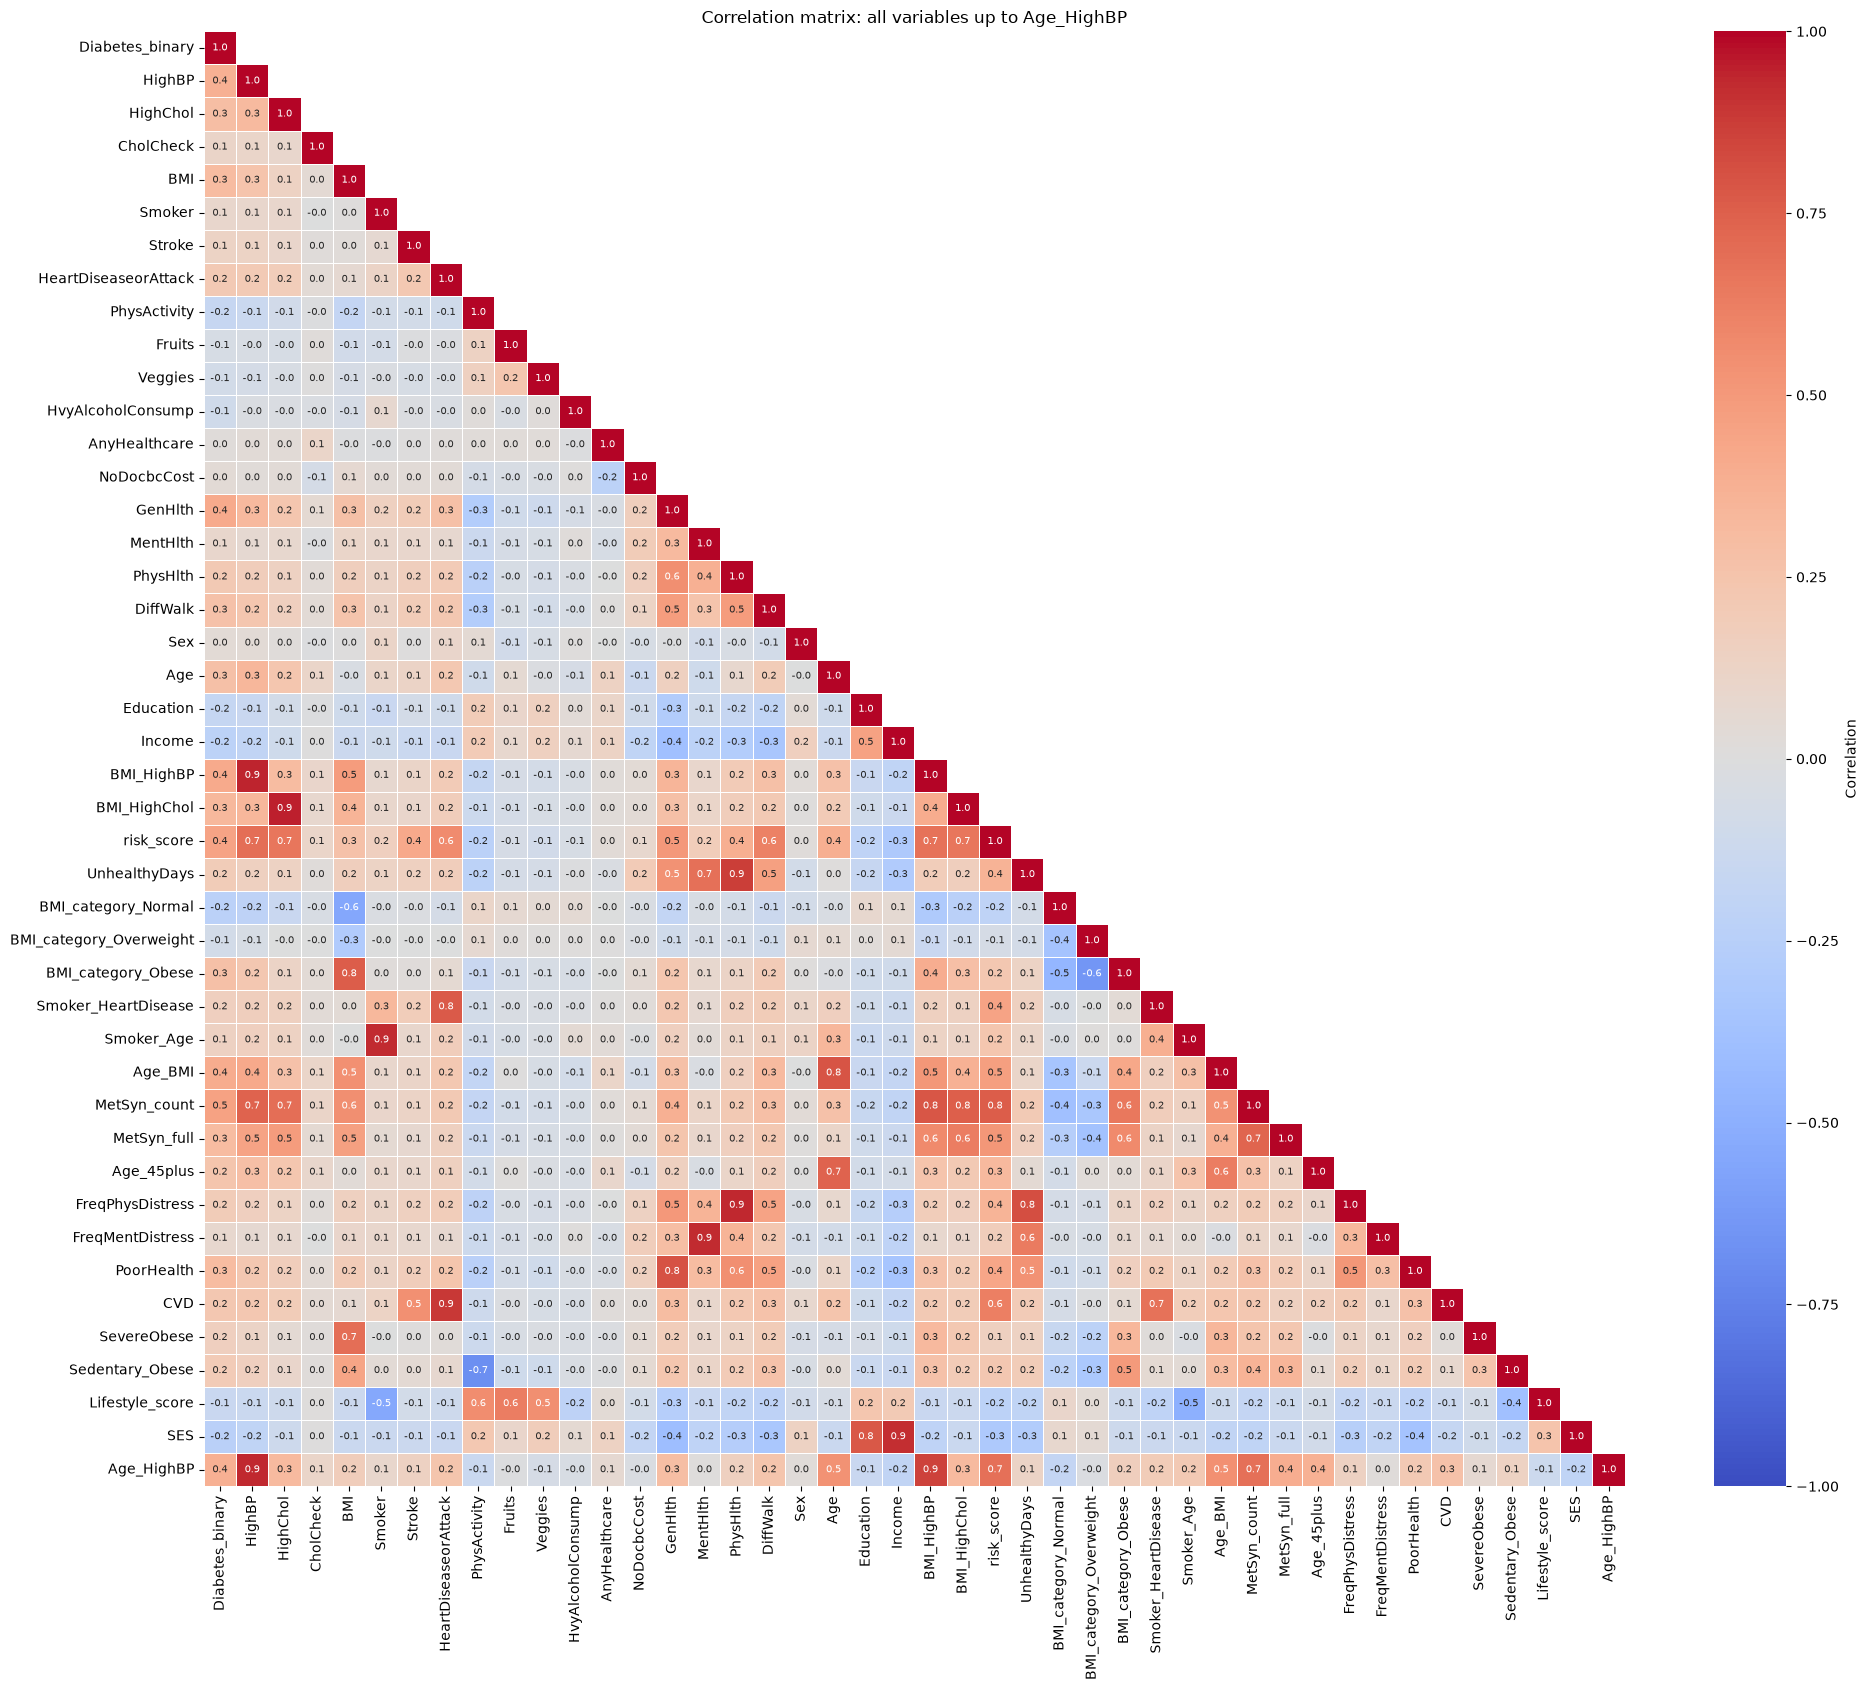

In [108]:
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(20, 17))
sns.heatmap(
    corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".1f", annot_kws={"size": 7},
    linewidths=0.5, cbar_kws={"label": "Correlation"}
)
plt.title("Correlation matrix: all variables up to Age_HighBP")
plt.tight_layout()
plt.show()

In [109]:
target_corr = corr["Diabetes_binary"].drop("Diabetes_binary")
display(target_corr.reindex(target_corr.abs().sort_values(ascending=False).index))

MetSyn_count               0.454116
risk_score                 0.449149
BMI_HighBP                 0.409085
GenHlth                    0.407612
Age_BMI                    0.403388
HighBP                     0.381516
Age_HighBP                 0.380900
BMI_HighChol               0.328722
MetSyn_full                0.308946
PoorHealth                 0.306559
BMI                        0.304891
HighChol                   0.289213
Age                        0.278738
BMI_category_Obese         0.275264
DiffWalk                   0.272646
Age_45plus                 0.249054
SES                       -0.235996
BMI_category_Normal       -0.231596
CVD                        0.226706
Income                    -0.224449
PhysHlth                   0.213081
HeartDiseaseorAttack       0.211523
Sedentary_Obese            0.199793
FreqPhysDistress           0.194330
UnhealthyDays              0.192565
Education                 -0.170481
Smoker_HeartDisease        0.162790
SevereObese                0

In [110]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.index.get_level_values(0) != "Diabetes_binary"]
display(pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False))

HighChol              BMI_HighChol        0.948109
HighBP                BMI_HighBP          0.943835
                      Age_HighBP          0.936212
PhysHlth              FreqPhysDistress    0.934932
Smoker                Smoker_Age          0.924750
MentHlth              FreqMentDistress    0.923554
Income                SES                 0.917378
HeartDiseaseorAttack  CVD                 0.883975
PhysHlth              UnhealthyDays       0.869908
BMI_HighBP            Age_HighBP          0.857440
UnhealthyDays         FreqPhysDistress    0.817728
GenHlth               PoorHealth          0.801795
dtype: float64

- `MetSyn_count` (metabolic syndrome proxy) has the strongest link with diabetes (0.45)
- Several new features are almost copies of their parts (r > 0.9, e.g. `BMI_HighBP` vs `HighBP`) → removed in the next step

## 4. Feature selection

1. Drop features with a weak link to the target (|r| < 0.1). `Sex` is kept, because studies show it matters for diabetes.
2. Drop redundant features (exact sums or near copies of other features) and features with a high VIF (variance inflation factor), which hurt Logistic Regression.

In [114]:
cols_drop_step1 = [
    "AnyHealthcare", 
    "NoDocbcCost",
    "Fruits", 
    "Veggies", 
    "Smoker",    
    "HvyAlcoholConsump",
    "MentHlth", 
    "FreqMentDistress",
    "BMI_category_Overweight",
]

df = df.drop(columns=cols_drop_step1)
df.shape

(70692, 35)

In [ ]:
# Train/test split (75/25), used here for the VIF check

X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"] 

X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=42)




In [ ]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

Xv = add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=X_train.columns).sort_values(ascending=False)
vif




BMI_category_Obese      8.254656e+07
SES                     1.658635e+07
Stroke                  9.717342e+06
HighBP                  6.567184e+06
Income                  6.432379e+06
HighChol                5.879547e+06
MetSyn_count            4.991073e+06
DiffWalk                2.594804e+06
Education               1.133353e+06
HeartDiseaseorAttack    4.331009e+05
risk_score              2.291332e+05
BMI_HighBP              3.621010e+01
BMI_HighChol            3.194882e+01
Age_BMI                 2.978865e+01
Age                     2.121019e+01
Age_HighBP              1.749737e+01
BMI                     1.686427e+01
PhysHlth                1.130775e+01
CVD                     1.118181e+01
FreqPhysDistress        7.970456e+00
UnhealthyDays           4.376099e+00
MetSyn_full             3.768027e+00
GenHlth                 3.393530e+00
PoorHealth              3.021565e+00
Smoker_HeartDisease     2.905878e+00
PhysActivity            2.840826e+00
SevereObese             2.784338e+00
S

In [120]:
# 2a. Remove redundant features
cols_drop_step2 = [
    "risk_score",            # exact sum of HighBP, HighChol, Stroke, HeartDisease, DiffWalk
    "SES",                   # exact sum of Income + Education
    "BMI_category_Obese",    # part of MetSyn_count and the same as BMI >= 30
    "BMI_category_Normal",   # continuous BMI already has this info
    "BMI_HighBP", "BMI_HighChol", "Age_HighBP",   # nearly identical to HighBP / HighChol
    "UnhealthyDays",         # nearly identical to PhysHlth
    "Smoker_HeartDisease", "Smoker_Age",           # already shown to add nothing
    "CVD",                   # is Stroke OR HeartDisease
]
df = df.drop(columns=cols_drop_step2)


In [121]:
# 2b. Reduce multicollinearity for Logistic Regression
cols_drop_step2b = [
    "Age_BMI",            # VIF 24.5, built from Age and BMI
    "FreqPhysDistress",   # VIF 8.0, nearly identical to PhysHlth (r = 0.93)
]
df = df.drop(columns=cols_drop_step2b)

In [134]:
df.shape

(70692, 22)

Final dataset: **21 features** (14 original and 7 new). `MetSyn_count` is tested in the next step.

## 5. Model comparison

6 models, each in a pipeline with `StandardScaler`, compared with 5-fold cross-validation on the training data. Two versions: with and without `MetSyn_count`.

In [128]:
# Final features and train/test split (75/25)
from sklearn.model_selection import cross_validate

X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

versions = {
    "with MetSyn": X_train,
    "without MetSyn": X_train.drop(columns=["MetSyn_count"]),
}

In [131]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   HighBP                70692 non-null  float64
 1   HighChol              70692 non-null  float64
 2   CholCheck             70692 non-null  float64
 3   BMI                   70692 non-null  float64
 4   Stroke                70692 non-null  float64
 5   HeartDiseaseorAttack  70692 non-null  float64
 6   PhysActivity          70692 non-null  float64
 7   GenHlth               70692 non-null  float64
 8   PhysHlth              70692 non-null  float64
 9   DiffWalk              70692 non-null  float64
 10  Sex                   70692 non-null  float64
 11  Age                   70692 non-null  float64
 12  Education             70692 non-null  float64
 13  Income                70692 non-null  float64
 14  MetSyn_count          70692 non-null  float64
 15  MetSyn_full           70692 no

In [132]:

classifiers = [
    LogisticRegression(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    KNeighborsClassifier(),
    GradientBoostingClassifier(),
    SVC()
]

# Every model is scaled with StandardScaler inside its pipeline
scaler = StandardScaler()

In [133]:

metrics = ["roc_auc", "recall", "precision", "f1"]
results = []

for version_name, Xv in versions.items():
    print(f"\n========== {version_name} ({Xv.shape[1]} variables) ==========")

    for clf in classifiers:
        model_name = type(clf).__name__
        pipe = make_pipeline(StandardScaler(), clf)
        cv = cross_validate(pipe, Xv, y_train, cv=5, scoring=metrics, n_jobs=-1)

        print(f"\n{model_name}")
        row = {"version": version_name, "model": model_name}
        for m in metrics:
            mean = cv[f"test_{m}"].mean()
            std = cv[f"test_{m}"].std()
            print(f"   {m:<10} {mean:.3f}  (± {std:.3f})")
            row[m] = mean
        results.append(row)

# final table with everything
res = pd.DataFrame(results).round(3)
res.sort_values("roc_auc", ascending=False)



========== with MetSyn (21 variables) ==========

LogisticRegression
   roc_auc    0.825  (± 0.001)
   recall     0.773  (± 0.004)
   precision  0.738  (± 0.002)
   f1         0.755  (± 0.002)

DecisionTreeClassifier
   roc_auc    0.660  (± 0.003)
   recall     0.651  (± 0.002)
   precision  0.663  (± 0.004)
   f1         0.657  (± 0.002)

RandomForestClassifier
   roc_auc    0.801  (± 0.002)
   recall     0.764  (± 0.003)
   precision  0.716  (± 0.002)
   f1         0.739  (± 0.002)

KNeighborsClassifier
   roc_auc    0.771  (± 0.004)
   recall     0.739  (± 0.001)
   precision  0.701  (± 0.003)
   f1         0.720  (± 0.002)

GradientBoostingClassifier
   roc_auc    0.828  (± 0.001)
   recall     0.794  (± 0.004)
   precision  0.730  (± 0.001)
   f1         0.761  (± 0.002)

SVC
   roc_auc    0.808  (± 0.003)
   recall     0.794  (± 0.008)
   precision  0.727  (± 0.004)
   f1         0.759  (± 0.005)

========== without MetSyn (20 variables) ==========

LogisticRegression
   roc_auc

,version,model,roc_auc,recall,precision,f1
10,without MetSyn,GradientBoostingClassifier,0.829,0.793,0.731,0.761
4,with MetSyn,GradientBoostingClassifier,0.828,0.794,0.730,0.761
0,with MetSyn,LogisticRegression,0.825,0.773,0.738,0.755
6,without MetSyn,LogisticRegression,0.825,0.771,0.738,0.754
11,without MetSyn,SVC,0.809,0.792,0.728,0.759
5,with MetSyn,SVC,0.808,0.794,0.727,0.759
8,without MetSyn,RandomForestClassifier,0.802,0.767,0.717,0.741
2,with MetSyn,RandomForestClassifier,0.801,0.764,0.716,0.739
9,without MetSyn,KNeighborsClassifier,0.771,0.738,0.701,0.719
3,with MetSyn,KNeighborsClassifier,0.771,0.739,0.701,0.720


- **Gradient Boosting** (ROC-AUC 0.829, recall 0.793) and **Logistic Regression** (ROC-AUC 0.825, recall 0.771) are the best → tuned in the next step
- SVC has a similar recall but a lower ROC-AUC; Decision Tree is clearly the weakest (ROC-AUC 0.66)
- `MetSyn_count` adds nothing (same scores with and without it) → dropped for a simpler model (20 features)

## 6. Hyperparameter tuning

`GridSearchCV` with 5-fold cross-validation, optimised for ROC-AUC.

In [136]:
# final data, without MetSyn

X_train_final = X_train.drop(columns=["MetSyn_count"])
X_test_final  = X_test.drop(columns=["MetSyn_count"])
X_train_final.shape, X_test_final.shape


((53019, 20), (17673, 20))

### Logistic Regression

Tuned: regularisation strength `C` (default 1.0).

In [ ]:


param_grid_logreg = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100]
}

pipe = make_pipeline(StandardScaler(),
                     LogisticRegression(solver="liblinear", max_iter=1000))

grid_logreg = GridSearchCV(pipe, param_grid_logreg, cv=5,
                           scoring=["roc_auc", "recall", "precision", "f1"],
                           refit="roc_auc", n_jobs=-1)
grid_logreg.fit(X_train_final, y_train)

i = grid_logreg.best_index_
r = grid_logreg.cv_results_
print("Best parameters:", grid_logreg.best_params_)
for m in ["roc_auc", "recall", "precision", "f1"]:
    print(f"   {m:<10} {r[f'mean_test_{m}'][i]:.3f}")

Best parameters: {'logisticregression__C': 0.01}
   roc_auc    0.825
   recall     0.771
   precision  0.739
   f1         0.754


No real gain: ROC-AUC 0.825 and recall 0.771 before and after tuning (best `C` = 0.01).

### Gradient Boosting

Tuned: number of trees, learning rate and tree depth.

In [138]:
# GradientBoosting

param_grid_gb = {
    "gradientboostingclassifier__n_estimators": [100, 200],
    "gradientboostingclassifier__learning_rate": [0.05, 0.1],
    "gradientboostingclassifier__max_depth": [3, 4, 5],
}

pipe = make_pipeline(StandardScaler(),
                     GradientBoostingClassifier(random_state=42))

grid_gb = GridSearchCV(pipe, param_grid_gb, cv=5,
                       scoring=["roc_auc", "recall", "precision", "f1"],
                       refit="roc_auc", n_jobs=-1)
grid_gb.fit(X_train_final, y_train)

i = grid_gb.best_index_
r = grid_gb.cv_results_
print("Best parameters:", grid_gb.best_params_)
for m in ["roc_auc", "recall", "precision", "f1"]:
    print(f"   {m:<10} {r[f'mean_test_{m}'][i]:.3f}")


Best parameters: {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__n_estimators': 200}
   roc_auc    0.829
   recall     0.796
   precision  0.731
   f1         0.762


Small gain in recall: from 0.793 to 0.796 (ROC-AUC stays at 0.829).

## 7. Final evaluation

### Training data

===== logreg (TRAIN) =====
roc_auc 0.825
recall  0.771
f1      0.755
params  {'logisticregression__C': 0.01}



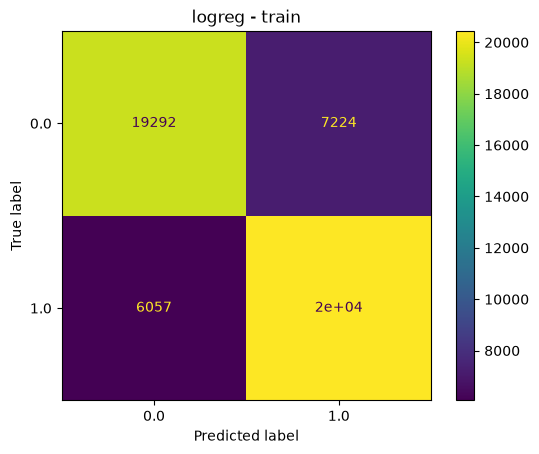

===== gradientboosting (TRAIN) =====
roc_auc 0.835
recall  0.802
f1      0.768
params  {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__n_estimators': 200}



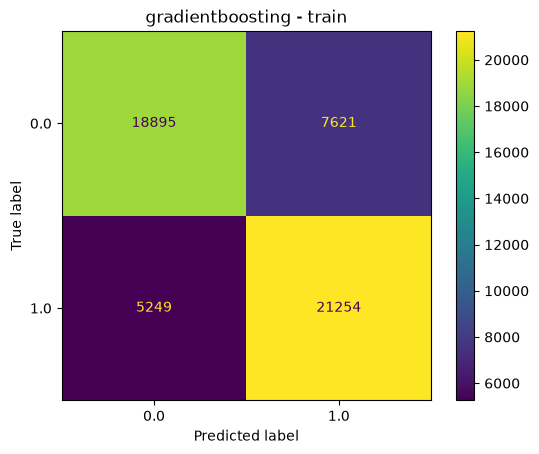

In [141]:
trained_models = {
    "logreg": grid_logreg,
    "gradientboosting": grid_gb,
}

for name, model in trained_models.items():
    y_pred = model.predict(X_train_final)
    y_proba = model.predict_proba(X_train_final)[:, 1]

    auc = roc_auc_score(y_train, y_proba)
    rec = recall_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)

    print(f"===== {name} (TRAIN) =====")
    print(f"roc_auc {auc:.3f}")
    print(f"recall  {rec:.3f}")
    print(f"f1      {f1:.3f}")
    print(f"params  {model.best_params_}")
    print()

    ConfusionMatrixDisplay.from_estimator(model, X_train_final, y_train)
    plt.title(f"{name} - train")
    plt.show()



### Test data

===== Logistic Regression (TEST) =====
   roc_auc  0.825
   recall   0.769
   f1       0.752



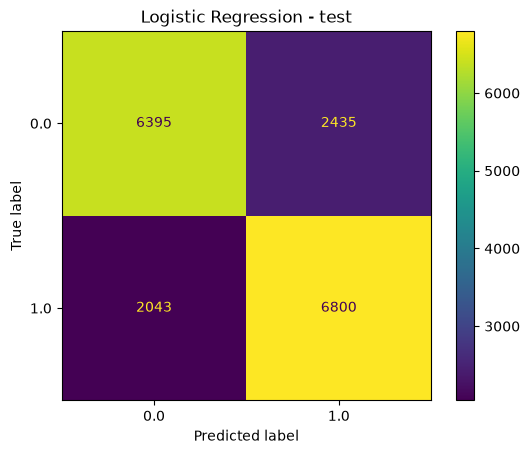

===== Gradient Boosting (TEST) =====
   roc_auc  0.830
   recall   0.798
   f1       0.763



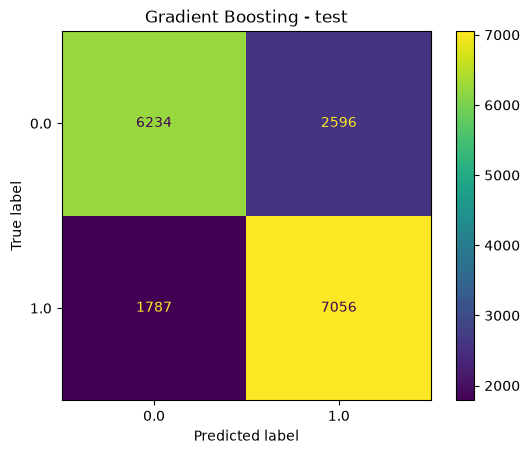

In [143]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test_final)
    y_proba = model.predict_proba(X_test_final)[:, 1]

    print(f"===== {name} (TEST) =====")
    print(f"   roc_auc  {roc_auc_score(y_test, y_proba):.3f}")
    print(f"   recall   {recall_score(y_test, y_pred):.3f}")
    print(f"   f1       {f1_score(y_test, y_pred):.3f}\n")

    ConfusionMatrixDisplay.from_estimator(model, X_test_final, y_test)
    plt.title(f"{name} - test")
    plt.show()

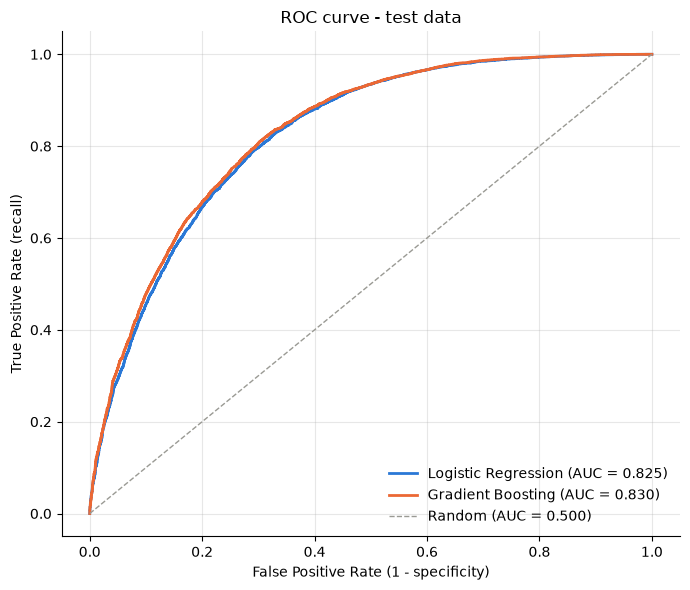

In [142]:
from sklearn.metrics import roc_curve

trained_models = {
    "Logistic Regression": grid_logreg,
    "Gradient Boosting": grid_gb,
}
colors = ["#2a78d6", "#eb6834"]

fig, ax = plt.subplots(figsize=(7, 6))

for (name, model), color in zip(trained_models.items(), colors):
    y_proba = model.predict_proba(X_test_final)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{name} (AUC = {auc:.3f})")

# random-guess baseline
ax.plot([0, 1], [0, 1], color="#9a9a94", linewidth=1,
        linestyle="--", label="Random (AUC = 0.500)")

ax.set_xlabel("False Positive Rate (1 - specificity)")
ax.set_ylabel("True Positive Rate (recall)")
ax.set_title("ROC curve - test data")
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Model | ROC-AUC | Recall | F1 |
|---|---|---|---|
| Logistic Regression | 0.825 | 0.769 | 0.752 |
| **Gradient Boosting** | **0.830** | **0.798** | **0.763** |

- Train and test scores are almost the same (Gradient Boosting ROC-AUC 0.835 vs 0.830) → no overfitting
- Gradient Boosting finds **7,056 of 8,843** people with diabetes in the test set (recall 0.80), with 2,596 false alarms (precision 0.73)

## 8. Feature importance

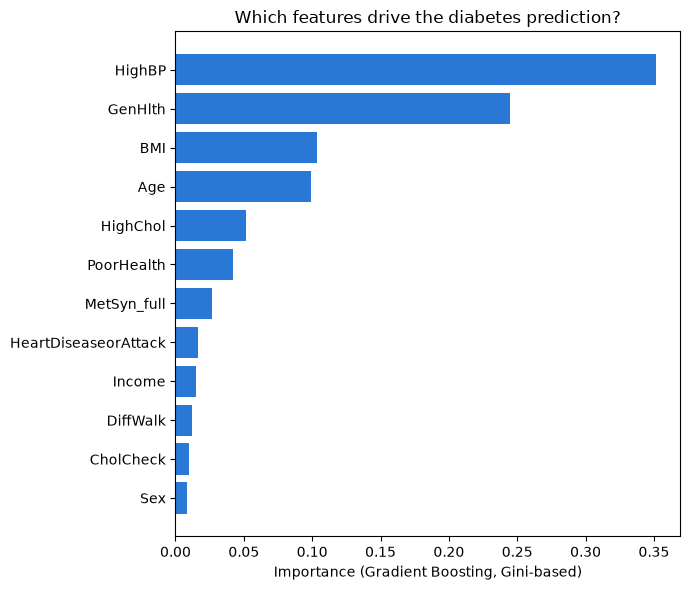

HighBP                  0.3515
GenHlth                 0.2450
BMI                     0.1036
Age                     0.0992
HighChol                0.0518
PoorHealth              0.0423
MetSyn_full             0.0268
HeartDiseaseorAttack    0.0168
Income                  0.0150
DiffWalk                0.0120
CholCheck               0.0096
Sex                     0.0086
Age_45plus              0.0050
Education               0.0040
Lifestyle_score         0.0027
Stroke                  0.0026
PhysHlth                0.0022
SevereObese             0.0008
PhysActivity            0.0004
Sedentary_Obese         0.0001
dtype: float64

In [144]:
# Feature importance from the tuned Gradient Boosting model
gb_model = grid_gb.best_estimator_.named_steps["gradientboostingclassifier"]
importances = pd.Series(gb_model.feature_importances_, index=X_train_final.columns).sort_values(ascending=False)

top = importances.head(12).sort_values()
plt.figure(figsize=(7, 6))
plt.barh(top.index, top.values, color="#2a78d6")
plt.xlabel("Importance (Gini-based)")
plt.title("Which features drive the diabetes prediction?")
plt.tight_layout()
plt.show()

importances.round(4)


- **High blood pressure dominates** (35% of the model's decisions), followed by **general self-rated health** (25%)
- **BMI and Age** matter clearly (10% each), then **high cholesterol** (5%)
- The **metabolic syndrome proxy** (`MetSyn_full`) adds real signal (2.7%) despite correlating with its parts
- **Lifestyle and access features** (physical activity, income, education) barely move the model on their own — their effect is mostly already captured through BMI, blood pressure and general health
- This matches the correlation matrix from section 3: the features with the strongest raw correlation with the target are also the ones Gradient Boosting relies on most

## 9. Conclusions

- **Best model: Gradient Boosting** (see section 8 for feature importance): recall 0.80, precision 0.73 and ROC-AUC 0.83 on the test set, close to Logistic Regression (recall 0.77, ROC-AUC 0.83)
- **Strongest links with diabetes:** high blood pressure, general health, BMI, age and the metabolic syndrome proxy; income, education and physical activity are protective
- Most of the signal comes from a few clinical features, so a simple, explainable model like Logistic Regression is almost as good
